# Distribuição e desigualdade do desempenho

**Área de análise:** Pará (PA)\
**Referência territorial:** município da escola (ESC)\
**Período:** 1998--2025 para o painel municipal e os grupos escolares;
2001--2023 para o detalhamento por sexo e faixa etária.\
**Fontes:** `painel`, `faixa` ,`grupo`,`dsp`.


**OBJETIVO**

Entender como as notas do ENEM se distribuem ao longo do tempo, se a dispersão dos resultados aumentou ou diminuiu, qual é a distância entre os segmentos de menor e maior desempenho e como essas diferenças se manifestam entre municípios, disciplinas e grupos de participantes.

---

<div style="background-color: #f5f0dc; padding: 12px; border-radius: 6px;">
    
> **Nota Metodológica**\
>  as médias apresentadas são ponderadas pelo número de notas válidas. Já medianas, quartis e IQR apresentados no painel são resumos das estatísticas municipais. Não representam os quartis ou a mediana calculados diretamente sobre todas as notas individuais dos participantes do Pará. O desvio-padrão combinado é uma aproximação construída a partir das estatísticas municipais e deve ser interpretado com essa ressalva.
</div>
 
### Principais achados
<div style="background-color: #DBEAFE; padding: 12px; border-radius: 6px;">

> **Ampliação da dispersão em Matemática**  
> O desvio-padrão combinado aproximado passou de **77,6 pontos em 2009 para 105,5 em 2025**. O IQR mediano municipal também aumentou, de 81,4 para 110,0 pontos.

> **As diferenças entre faixas etárias são as mais amplas**  
> Em 2023, a amplitude mediana municipal entre faixas etárias chegou a **284,6 pontos em Redação** e **112,8 em Matemática**, superando as amplitudes observadas por sexo e dependência administrativa.

> **Diferenças entre redes escolares são expressivas**  
> Em 2025, a diferença entre as médias ponderadas das escolas privadas e estaduais foi de aproximadamente **234,1 pontos em Redação** e **120,6 em Matemática**.

 </div>

---

## Configuração e carga

In [1]:
from _setup2 import *

UF_PROCESSAMENTO = "PA"
TIPO_REFERENCIA = "ESC"

out = read_allfiles2(UF_PROCESSAMENTO, TIPO_REFERENCIA)

painel = out["painel"]["data"].copy()
faixa = out["faixa"]["data"].copy()
grupo = out["grupo"]["data"].copy()
dsp = out["dsp"]["data"].copy()

desempenho_municipal = eda2.preparar_desempenho_municipal_eixo6(painel, TIPO_REFERENCIA)
grupo_preparado = eda2.preparar_grupos_desempenho_eixo6(grupo, TIPO_REFERENCIA)
dsp_preparado = eda2.preparar_dsp_detalhado_eixo6(dsp, TIPO_REFERENCIA)
composicao_etaria = eda2.resumir_composicao_etaria_eixo6(faixa, TIPO_REFERENCIA)
serie_anual = eda2.resumir_distribuicao_municipal_eixo6(desempenho_municipal)
ANO_INICIO = 2002      

print("=" * 46)
print(f"UF: {UF_PROCESSAMENTO}  | Período :{painel['ano'].min()}–{painel['ano'].max()}| Referência: {TIPO_REFERENCIA} ")
print("=" * 46)
print(f"painel  : {painel.shape[0]:,} x {painel.shape[1]}".replace(",", "."))
print(f"faixa   : {faixa.shape[0]:,} x {faixa.shape[1]}".replace(",", "."))
print(f"grupo   : {grupo.shape[0]:,} x {grupo.shape[1]}".replace(",", "."))
print(f"dsp     : {dsp.shape[0]:,} x {dsp.shape[1]}".replace(",", "."))
print("=" * 46)

UF: PA  | Período :1998–2025| Referência: ESC 
painel  : 3.625 x 82
faixa   : 38.335 x 7
grupo   : 186.449 x 16
dsp     : 250.436 x 17


## 1. Como evoluiu a dispersão das notas ao longo dos anos?

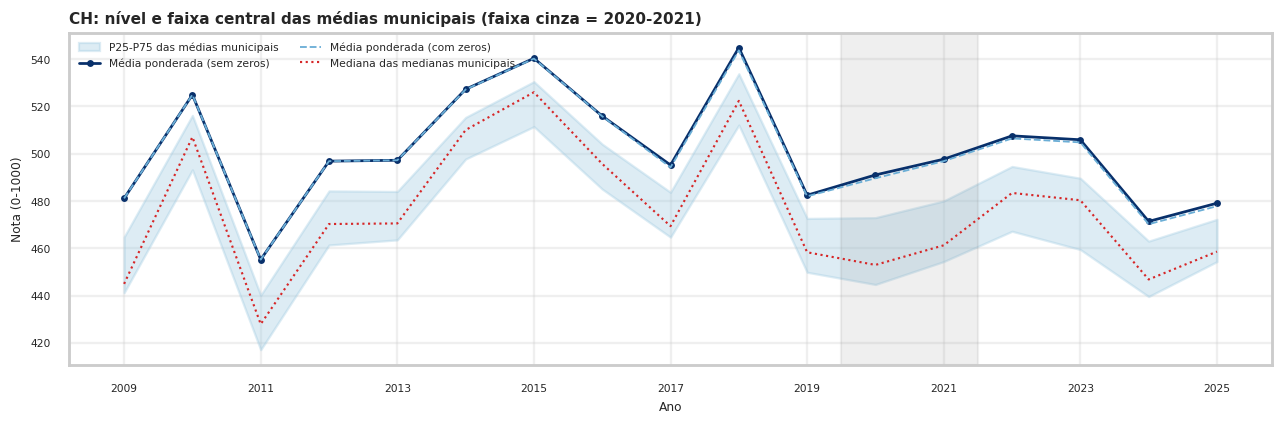

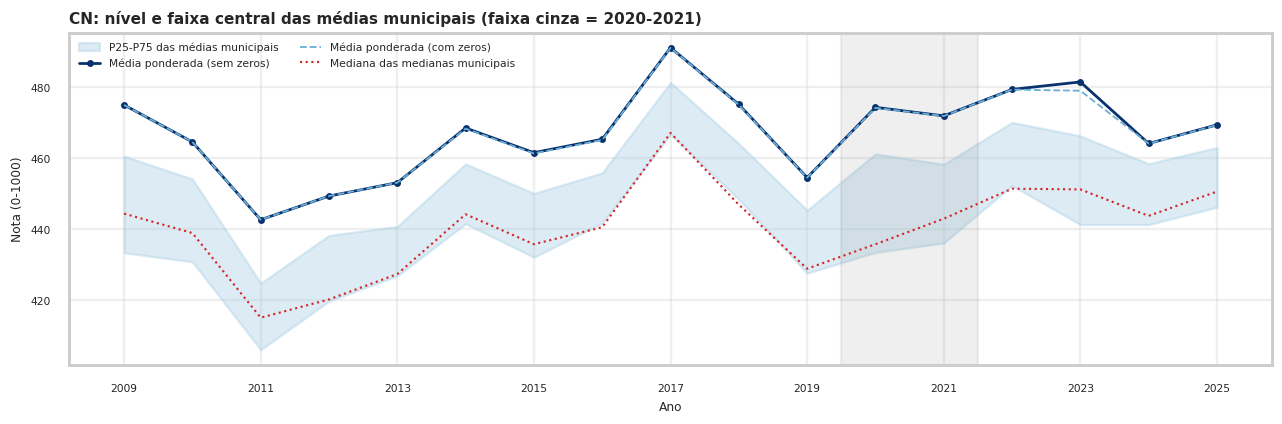

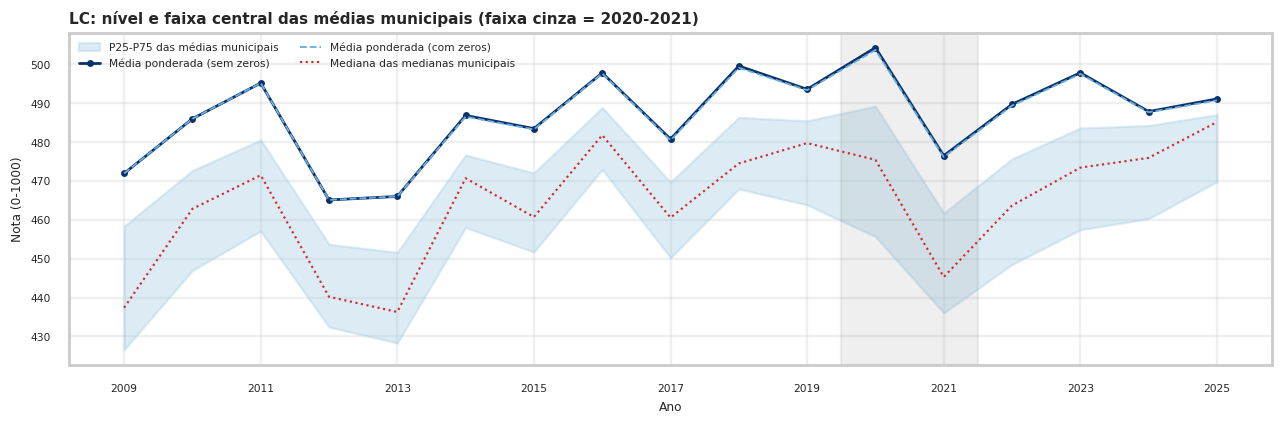

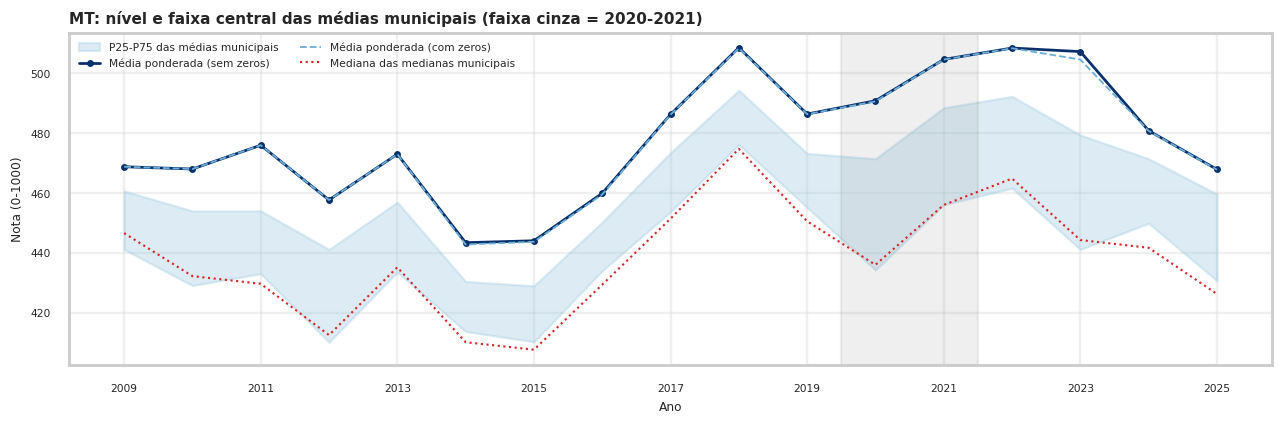

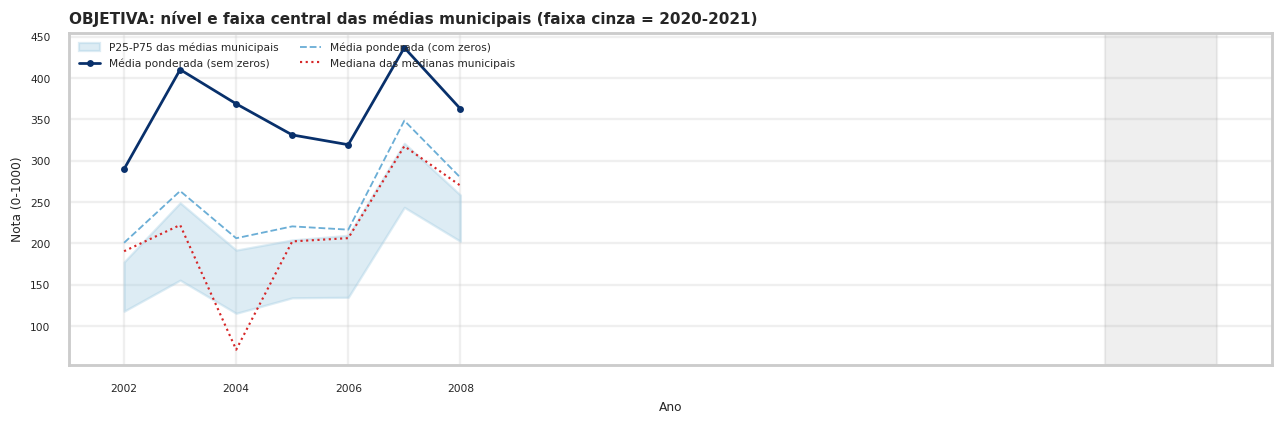

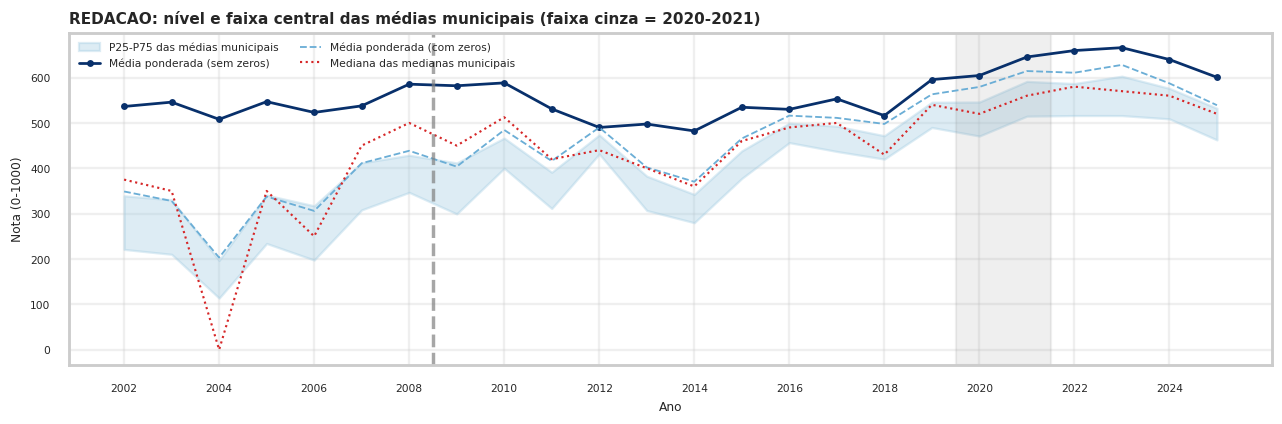

In [2]:
def plot_nivel(g, disciplina):
    g = g[g.ano >= ANO_INICIO].sort_values("ano")
    x = g["ano"]

    fig, ax = plt.subplots(figsize=(12, 4.2))

    ax.fill_between(x, g.p25_medias_municipais, g.p75_medias_municipais,
                    color="#9ecae1", alpha=0.35, label="P25-P75 das médias municipais")
    ax.plot(x, g.media_ponderada_sem_zero, marker="o", ms=3.5, lw=1.8,
            color="#08306b", label="Média ponderada (sem zeros)")
    ax.plot(x, g.media_ponderada, ls="--", lw=1.2, color="#6baed6",
            label="Média ponderada (com zeros)")
    ax.plot(x, g.mediana_das_medianas_municipais, ls=":", lw=1.4,
            color="#d62728", label="Mediana das medianas municipais")

    ax.axvspan(2019.5, 2021.5, color="gray", alpha=0.12)          # pandemia
    if x.min() < 2008.5 < x.max():
        ax.axvline(2008.5, color="gray", ls="--", alpha=0.7)       # mudança de escala/prova
    ax.set_xticks(range(int(x.min()), int(x.max()) + 1, 2))
    ax.set_xlabel("Ano", fontsize=8)
    ax.set_ylabel("Nota (0-1000)", fontsize=8)
    ax.set_title(f"{disciplina}: nível e faixa central das médias municipais "
                 f"(faixa cinza = 2020-2021)", fontsize=10, fontweight="bold", loc="left")
    ax.tick_params(labelsize=7)
    ax.grid(alpha=0.3)
    ax.legend(frameon=False, fontsize=7, ncol=2, loc="upper left")
    plt.tight_layout()
    plt.show()

for disciplina, g in serie_anual.groupby("disciplina"):
    plot_nivel(g, disciplina)



### Comentário
A dispersão não apresentou uma trajetória uniforme entre as disciplinas.
No período do Novo ENEM (2009--2025), Ciências Humanas, Ciências da
Natureza e Linguagens apresentaram, em geral, redução do desvio-padrão
combinado aproximado entre o início e o final da série. Matemática
seguiu o sentido contrário, com aumento expressivo da dispersão nos anos
mais recentes. A Redação também apresentou redução em relação a 2009,
embora permaneça com dispersão muito superior à das provas objetivas.

A comparação entre 2009 e 2025 evidencia esses comportamentos:

 | Disciplina | Desvio-padrão aprox. 2009 | Desvio-padrão aprox. 2025 | IQR mediano municipal 2009 | IQR mediano municipal 2025 |
| --- | --- | --- | --- | --- |
| **CH** | 93,5 | 81,5 | 95,8 | 95,9 |
| **CN** | 90,8 | 73,4 | 94,4 | 92,5 |
| **LC** | 93,5 | 74,1 | 107,8 | 89,7 |
| **MT** | 77,6 | 105,5 | 81,4 | 110,0 |
| **Redação** | 293,1 | 238,8 | 553,1 | 220,0 |

*Valores arredondados. O IQR mediano municipal corresponde à mediana,
entre municípios, da diferença entre Q3 e Q1 de cada município.*

Em CH, CN e LC, a redução do desvio-padrão combinado indica menor
dispersão aproximada dos resultados quando consideradas as variações
internas e entre municípios. Em CN e LC, também houve redução do IQR
mediano municipal. Em CH, esse IQR permaneceu praticamente estável.

Matemática apresenta o comportamento mais preocupante nesse recorte: o
desvio-padrão combinado aproximado passou de 77,6 pontos em 2009 para
105,5 em 2025, enquanto o IQR mediano municipal aumentou de 81,4 para
110,0 pontos. O maior desvio-padrão da série para Matemática ocorreu em
2023, quando alcançou aproximadamente 120,8 pontos.

Na Redação, a dispersão permanece elevada, mas os indicadores diminuíram
em relação a 2009. O IQR mediano municipal passou de 553,1 para 220,0
pontos. Essa diferença deve ser interpretada com atenção, pois os
resultados municipais de Redação apresentam grande heterogeneidade e os
quartis municipais podem ser sensíveis à composição e ao número de
participantes.

**Interpretação:** não houve redução geral da dispersão do desempenho. A
variabilidade diminuiu em algumas áreas, permaneceu relativamente
estável em outras e aumentou de forma importante em Matemática. A
Redação mantém uma distribuição mais dispersa do que as provas
objetivas, mesmo após a redução observada nos indicadores.


## 2. Desigualdade e distância entre quartis

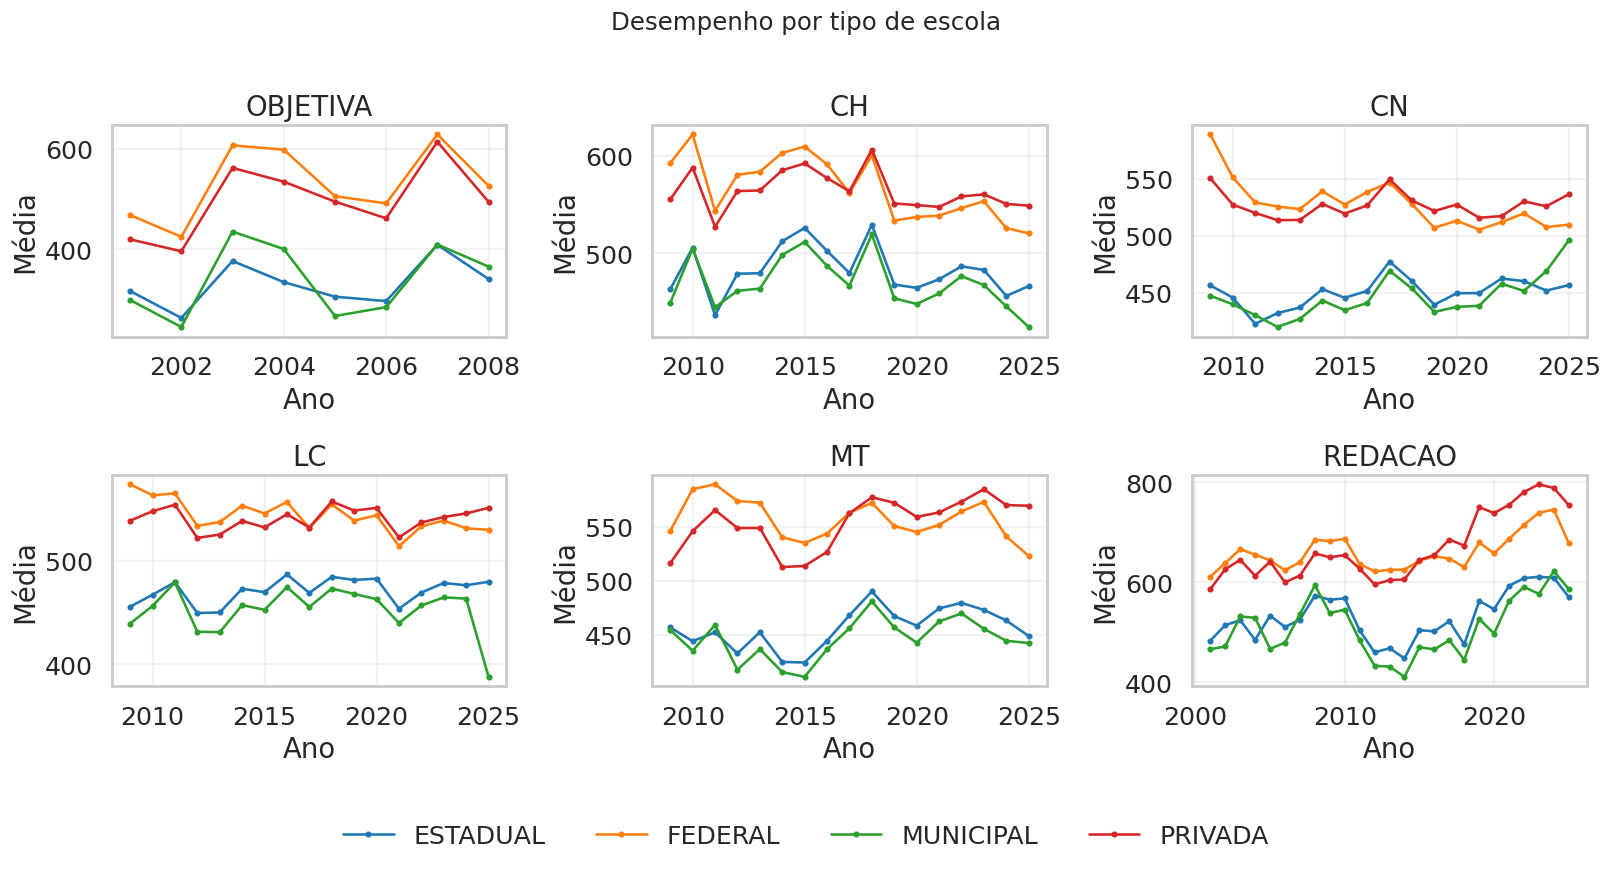

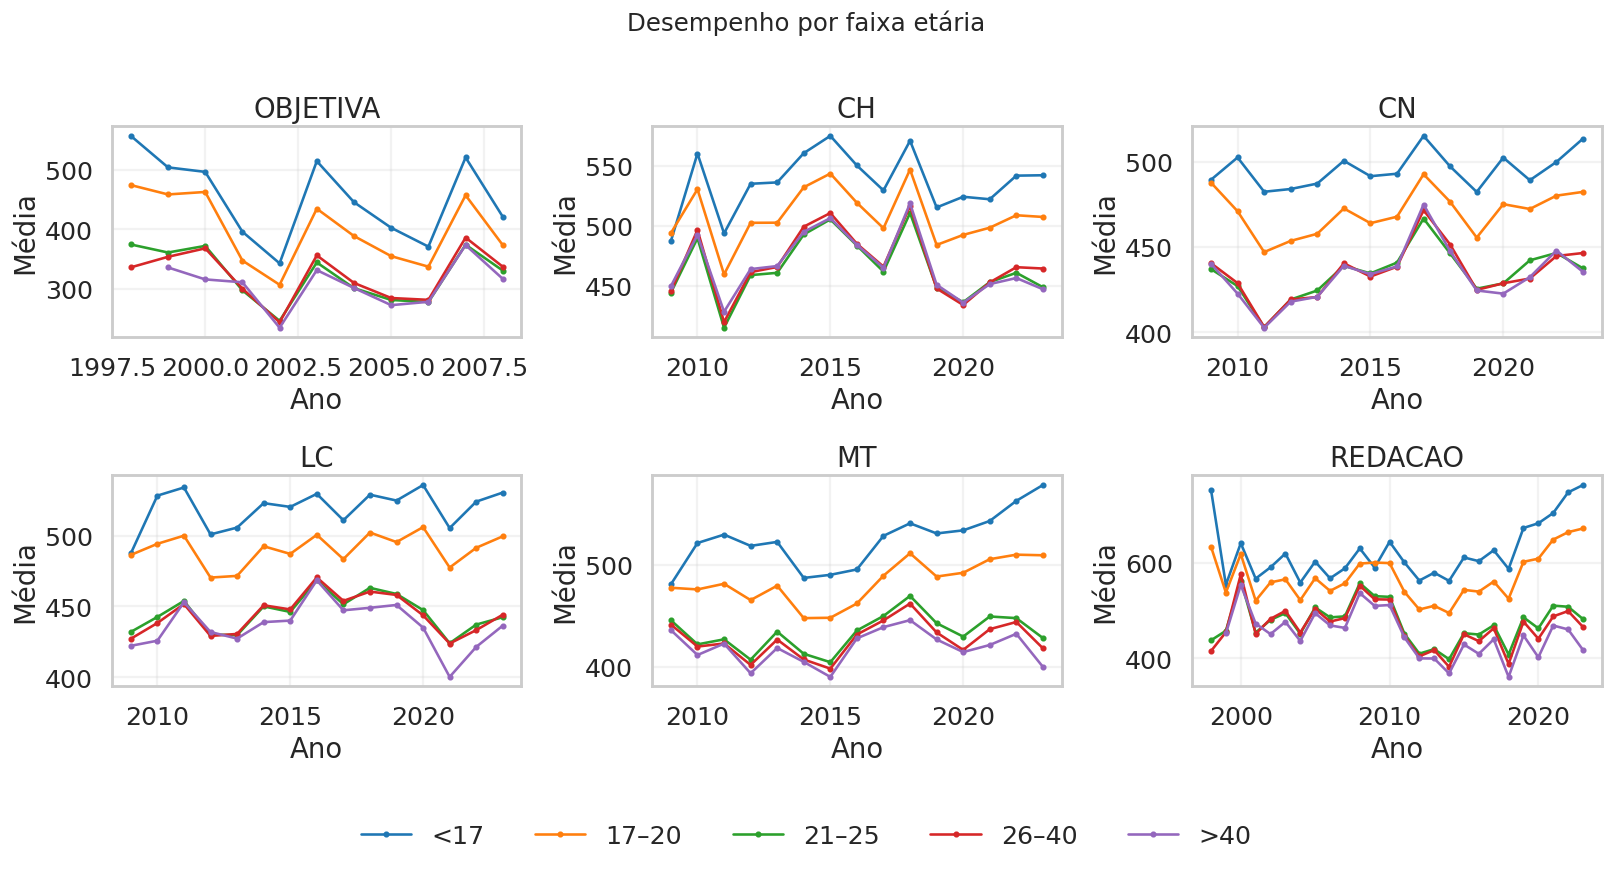

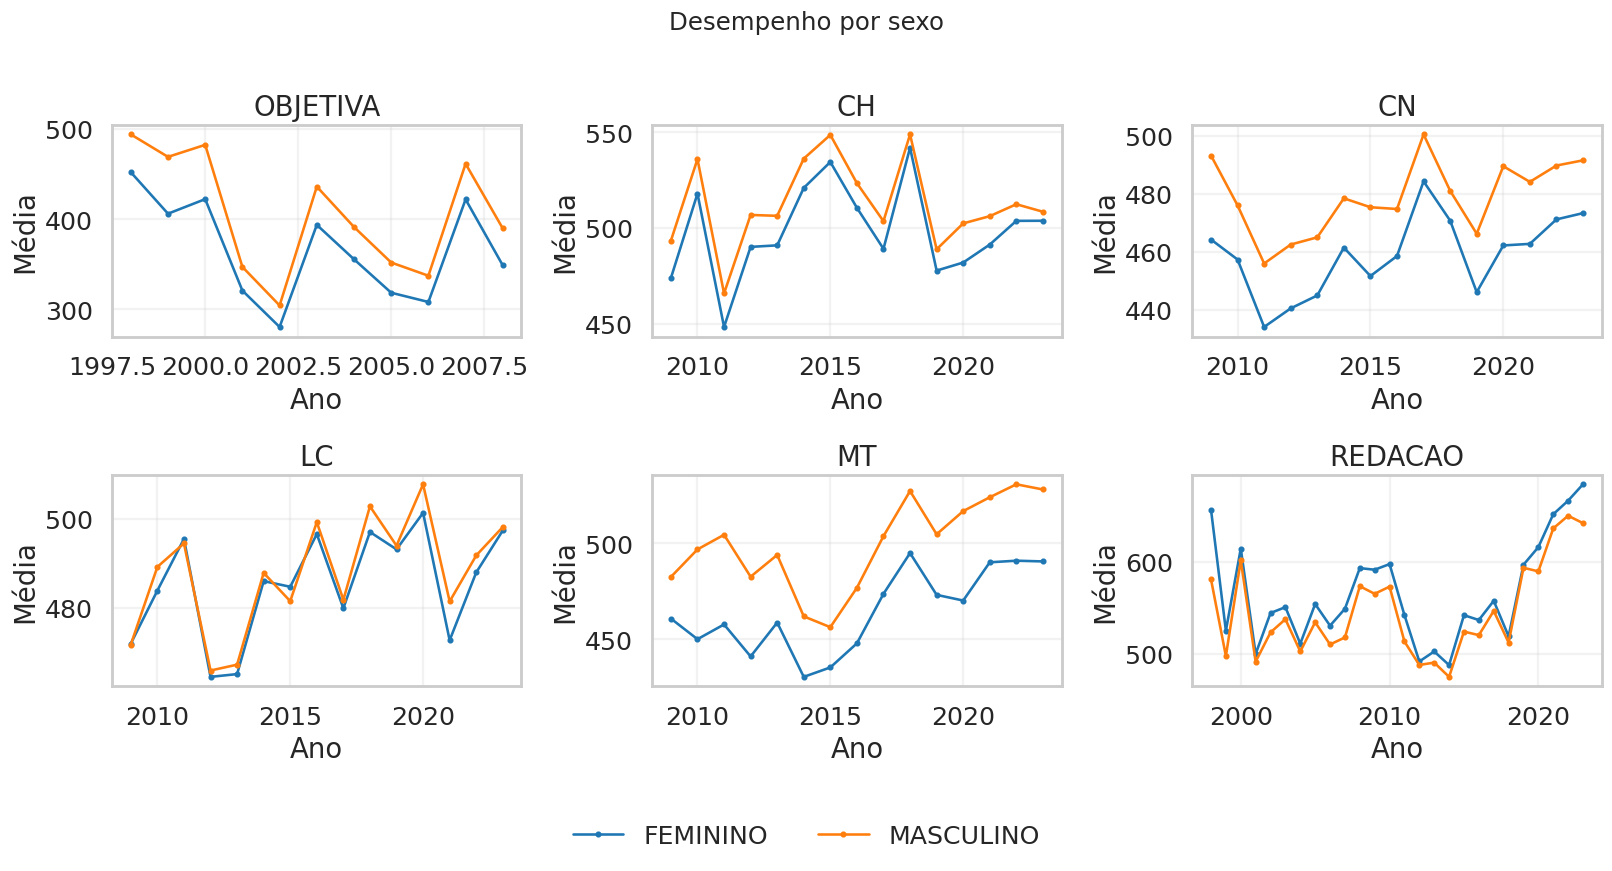

In [3]:
resumo_grupos = eda2.resumir_grupos_desempenho_eixo6(grupo_preparado)
eda2.plotar_resumo_grupos(resumo_grupos)

### Comentários
A resposta depende da disciplina e da dimensão utilizada. Os resultados não sustentam uma conclusão única de redução ou ampliação da desigualdade no conjunto do ENEM.

A comparação dos indicadores de dispersão entre 2009 e 2025 mostra redução em Ciências Humanas (CH), Ciências da Natureza (CN) e Linguagens (LC), mas ampliação em Matemática (MT). Na Redação, os indicadores selecionados diminuíram em relação a 2009, embora permaneçam elevados.

A evolução também apresenta oscilações intermediárias. Em 2023, por exemplo, Matemática alcançou desvio-padrão combinado aproximado de 120,8 pontos e IQR mediano municipal de 127,5 pontos. Em 2025, esses valores recuaram para 105,5 e 110,0 pontos, respectivamente, mas continuaram acima dos valores de 2009.

Na Redação, o IQR mediano municipal foi de 553,1 pontos em 2009, caiu para 200,0 em 2015 e voltou a 260,0 em 2023, chegando a 220,0 em 2025. Esse comportamento reforça que a dispersão não evolui de maneira linear.

**Diferenças entre grupos de escolas**

Os resultados de 2025 acrescentam outra dimensão à análise: as diferenças de desempenho entre dependências administrativas. As médias ponderadas das escolas privadas foram superiores às das escolas estaduais nas cinco disciplinas. As maiores diferenças foram observadas na Redação, com aproximadamente 234,1 pontos, e em Matemática, com 120,6 pontos. Em Ciências Humanas, Ciências da Natureza e Linguagens, as diferenças foram de aproximadamente 82,8, 79,7 e 71,9 pontos, respectivamente.

As escolas federais também apresentaram médias superiores às estaduais nas cinco disciplinas. Entretanto, esses resultados representam comparações entre grupos institucionais e não substituem os indicadores de dispersão territorial apresentados anteriormente. Além disso, os resultados das escolas municipais não permitem uma comparação estadual equivalente em 2025, pois o grupo contempla apenas um município.

A desigualdade de desempenho apresenta trajetórias específicas por disciplina e também diferenças entre grupos. Matemática merece atenção pela ampliação da dispersão ao longo do período, enquanto CH, CN e LC apresentam indicadores finais inferiores aos de 2009. Na Redação, apesar da redução em relação ao início da série, a dispersão continua elevada. A comparação por dependência administrativa mostra, adicionalmente, diferenças expressivas entre as médias dos grupos de escolas, sobretudo em Redação e Matemática.

É importante não confundir redução da dispersão municipal com redução da desigualdade individual entre estudantes. Os indicadores de dispersão apresentados permitem avaliar a variabilidade das estatísticas municipais e estimar a dispersão combinada, mas não reconstituem a distribuição individual completa das notas no estado. Da mesma forma, as diferenças entre médias de grupos de escolas não demonstram, isoladamente, os fatores responsáveis por essas diferenças.


## 3. Diferenças territoriais e entre grupos sociais

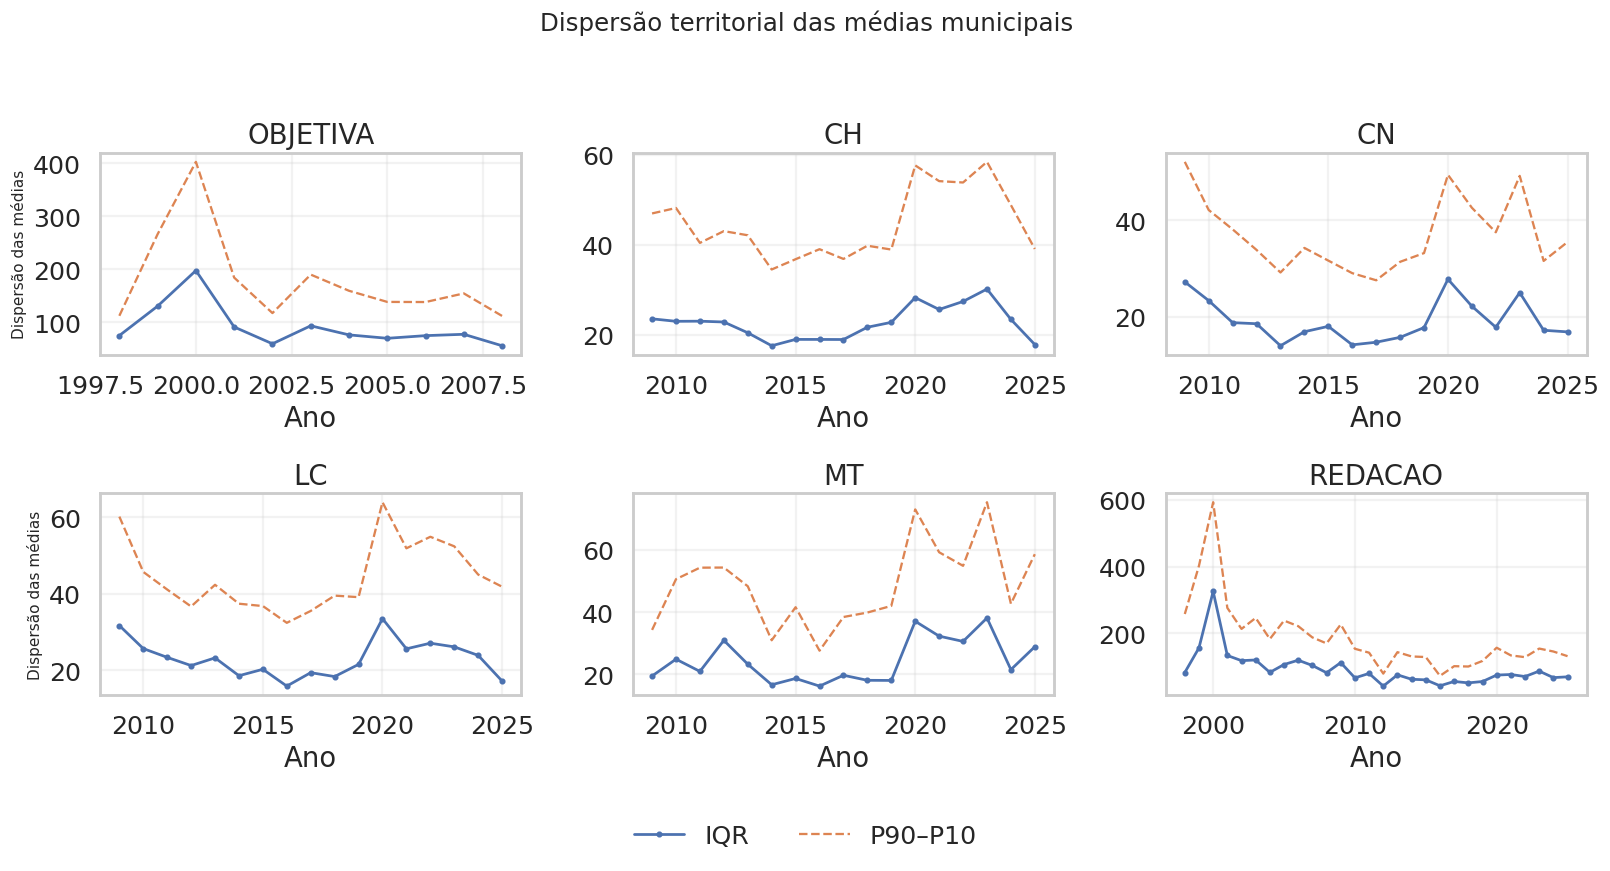

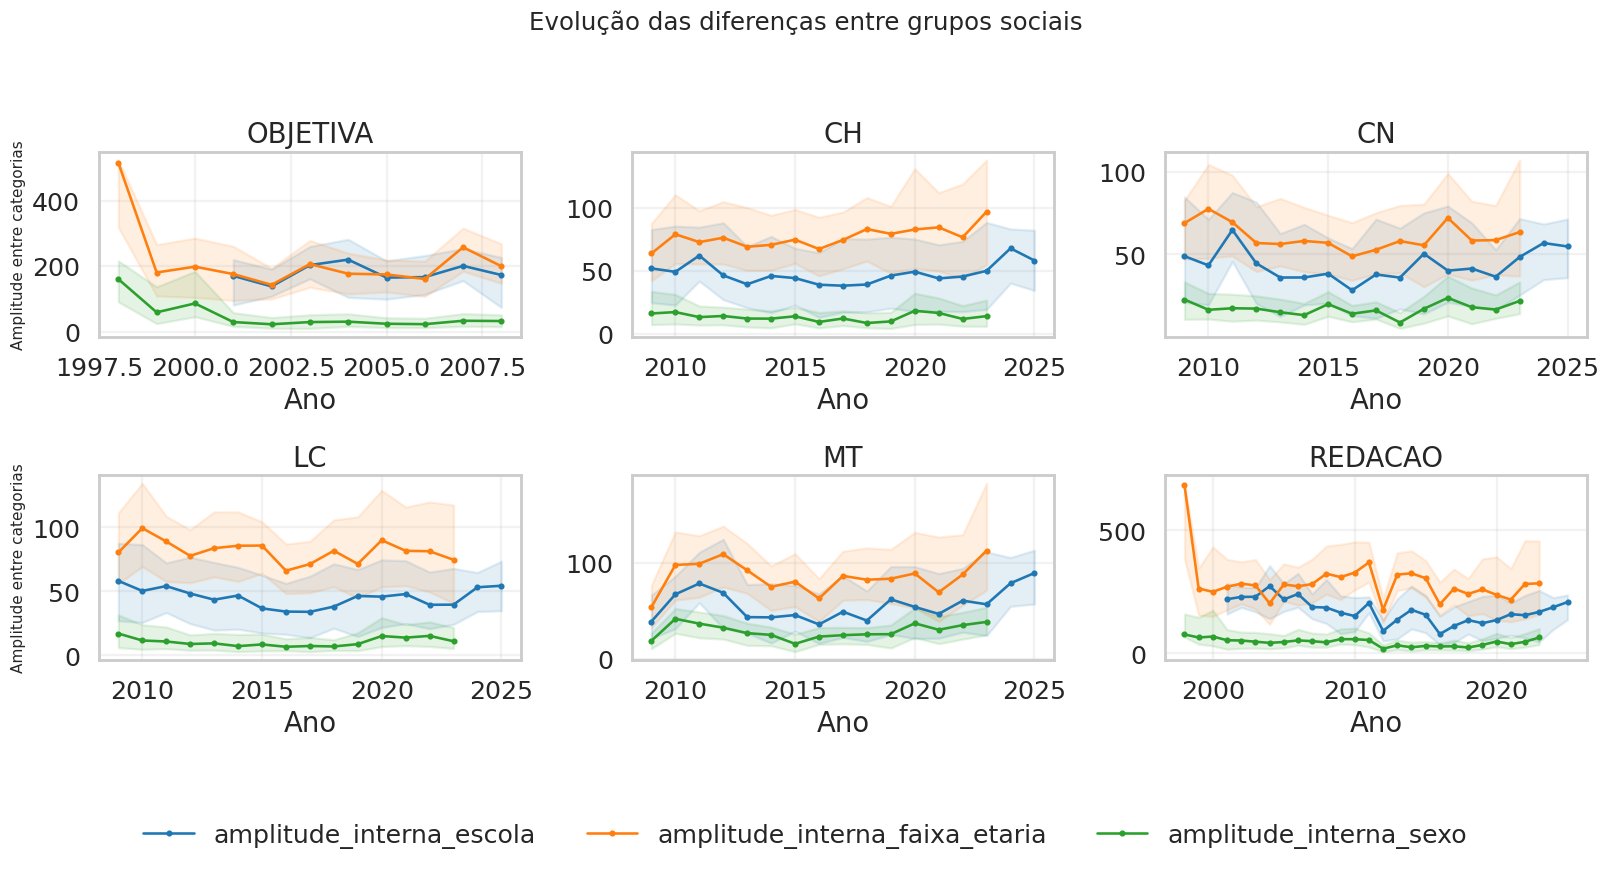

In [4]:
categorias_municipais, comparacao_d04 = eda2.calcular_disparidade_social_municipal_eixo6(grupo_preparado, desempenho_municipal)
eda2.plotar_comparacao_d04(comparacao_d04)


### Comentários

Os quartis permitem acompanhar a distribuição das médias municipais em cada disciplina. Para o conjunto do estado, a planilha apresenta o primeiro quartil (Q1 ou Q25) e o terceiro quartil (Q3 ou Q75) das médias dos municípios. Esses valores delimitam a faixa central de 50% dos municípios, e não os quartis das notas individuais dos participantes dentro de cada município.

Entre 2009 e 2025, observam-se mudanças distintas:

| Disciplina | Q1 2009 | Q3 2009 | Q1 2025 | Q3 2025 |
|---|---:|---:|---:|---:|
| CH | 441,2 | 464,8 | 454,4 | 472,2 |
| CN | 433,3 | 460,5 | 446,1 | 463,0 |
| LC | 426,6 | 458,3 | 469,8 | 487,0 |
| MT | 441,2 | 460,6 | 430,7 | 459,6 |
| Redação | 299,5 | 411,8 | 462,6 | 532,2 |

*Valores arredondados.*

* Em Ciências Humanas (CH) e Ciências da Natureza (CN), os dois quartis aumentaram moderadamente. Em Linguagens (LC), a elevação foi mais expressiva: o Q1 passou de 426,6 para 469,8 pontos, enquanto o Q3 subiu de 458,3 para 487,0. Esse comportamento indica uma elevação das referências inferiores e superiores da distribuição das médias municipais.

* Em Matemática (MT), ocorreu movimento diferente: o Q1 diminuiu de 441,2 para 430,7 pontos, enquanto o Q3 apresentou pequena redução, de 460,6 para 459,6. Além da queda dos dois quartis, a distância entre eles aumentou, indicando maior dispersão das médias municipais na faixa central da distribuição.

* Na Redação, os dois quartis apresentaram elevação expressiva. O Q1 passou de 299,5 para 462,6 pontos, e o Q3, de 411,8 para 532,2. A distância entre os quartis também diminuiu, sugerindo uma distribuição mais concentrada das médias municipais na faixa central, em comparação com 2009.

* CH e CN apresentaram aumento moderado dos dois quartis, enquanto LC e Redação registraram elevações mais acentuadas, especialmente no quartil inferior. Matemática se distingue pela redução dos quartis e pelo aumento da distância entre eles. Assim, os resultados apontam para mudanças diferentes na distribuição territorial do desempenho, sem indicar uma tendência única para todas as áreas.

É importante destacar que essa comparação descreve a distribuição das médias municipais. Ela não permite, isoladamente, concluir sobre a desigualdade entre participantes dentro dos municípios ou sobre as causas das diferenças observadas.

## 4. Distribuição dos resultados entre disciplinas

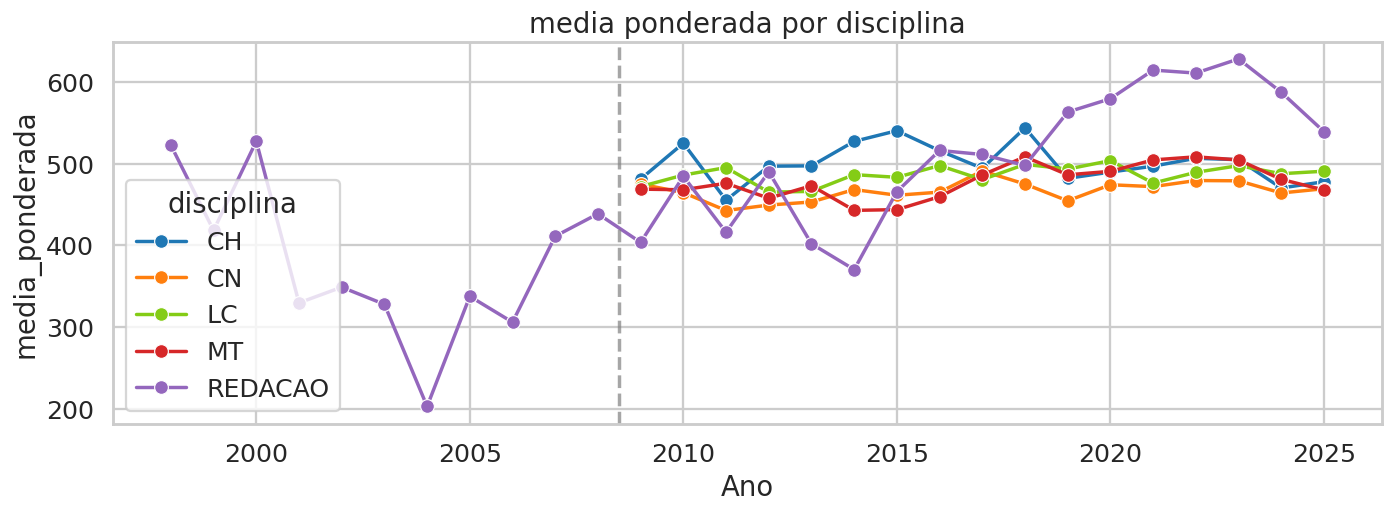

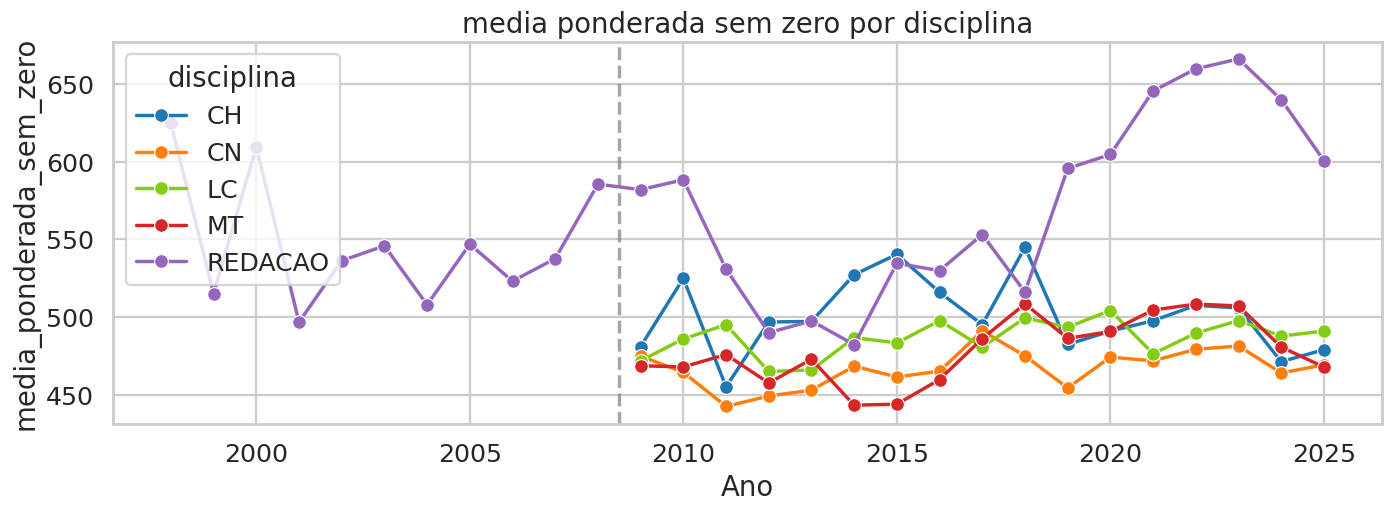

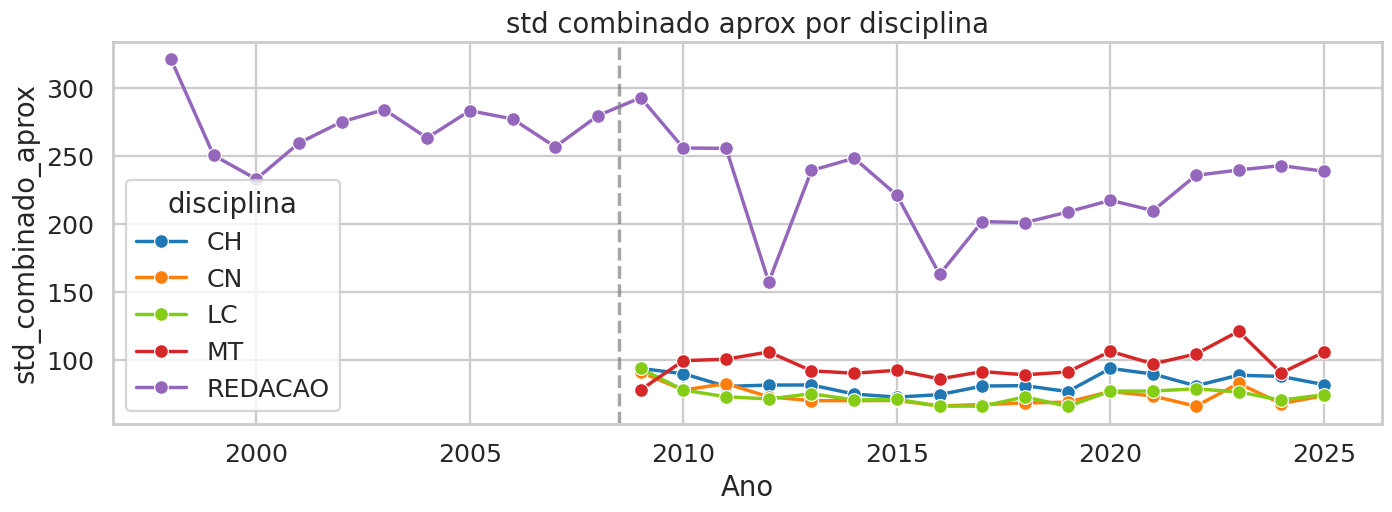

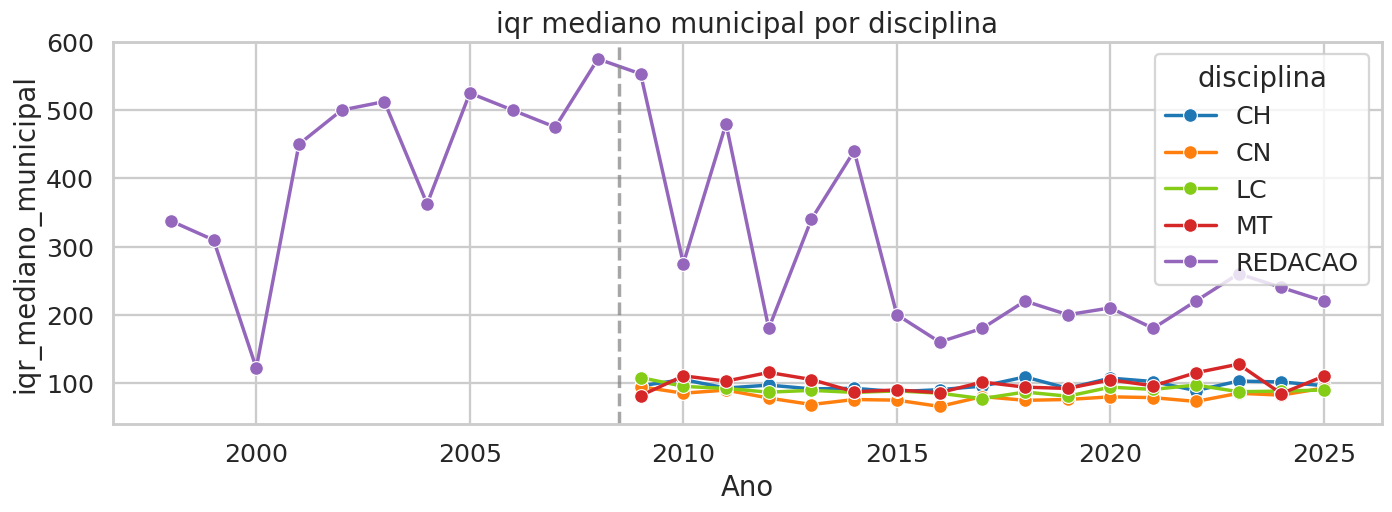

In [7]:
DISC5 = ["CH", "CN", "LC", "MT", "REDACAO"]
CORES = {"CH": "#1f77b4", "CN": "#ff7f0e", "LC": "#84cc16", "MT": "#d62728", "REDACAO": "#9467bd"}
for indicador in ["media_ponderada", "media_ponderada_sem_zero", "std_combinado_aprox", "iqr_mediano_municipal"]:
    fig, ax = plt.subplots(figsize=(13, 5))
    sns.lineplot(data=serie_anual, x="ano", y=indicador, hue="disciplina", hue_order=DISC5,
                palette=CORES,marker="o", ax=ax)
    ax.axvline(2008.5, color="gray", linestyle="--", alpha=.7)
    ax.set(title=f"{indicador.replace('_', ' ')} por disciplina", xlabel="Ano", ylabel=indicador)
    plt.tight_layout(); plt.show()


### Comentário
A análise compara, em cada município, a
amplitude entre as médias ponderadas das categorias de cada dimensão:
sexo, faixa etária e dependência administrativa da escola. Em seguida,
resume essas amplitudes entre os municípios. Assim, a comparação não
utiliza diretamente o desvio-padrão de 144 médias municipais contra o
desvio-padrão de apenas duas categorias de sexo.

Em 2023, último ano com informação de sexo e faixa etária nas fontes de
detalhamento, as amplitudes medianas municipais foram:

| **Dimensão de comparação** | **Municípios** | **CH** | **CN** | **LC** | **MT** | **Redação** |
| -------------------------- | -------------- | ------ | ------ | ------ | ------ | ----------- |
| **Sexo**                   | 139            | 14,3   | 21,8   | 10,9   | 38,6   | 64,1        |
| **Faixa etária**           | 124            | 97,2   | 63,5   | 74,7   | 112,8  | 284,6       |
| **Dependência escolar**    | 104            | 50,2   | 48,4   | 39,6   | 56,9   | 168,2       |

*(Valores das áreas expressos como amplitude mediana municipal em pontos.)*

As diferenças entre categorias de faixa etária foram, em geral, maiores
do que as diferenças entre categorias de sexo e de dependência
administrativa. A distância entre faixas etárias foi especialmente
elevada na Redação e em Matemática.

A comparação por sexo apresentou amplitudes menores em CH, CN e LC, mas
diferenças mais expressivas em Matemática e Redação. A dependência
administrativa apresentou amplitudes intermediárias, com maior distância
na Redação.

Entre as dimensões comparadas, a faixa etária
apresentou as maiores diferenças municipais em 2023. Isso não significa
que a idade, isoladamente, explique o desempenho: as categorias etárias
também podem refletir trajetórias escolares, condições socioeconômicas e
perfis distintos de participação no exame.

A comparação é descritiva. Não constitui decomposição causal da
desigualdade e não permite atribuir a uma dimensão específica a
responsabilidade pelas diferenças observadas.

Observação, sexo e faixa etária estão disponíveis para esta
comparação até 2023. A dependência administrativa apresenta registros em
2024 e 2025, mas a cobertura municipal das categorias sofreu forte
redução. Em 2025, por exemplo, a categoria municipal aparece com apenas
três notas válidas em uma localidade, não sendo adequada para uma
comparação estadual representativa. Por isso, 2023 é utilizado como
referência comum para a comparação entre as três dimensões.


## 5. Detalhamento complementar: desempenho e composição etária

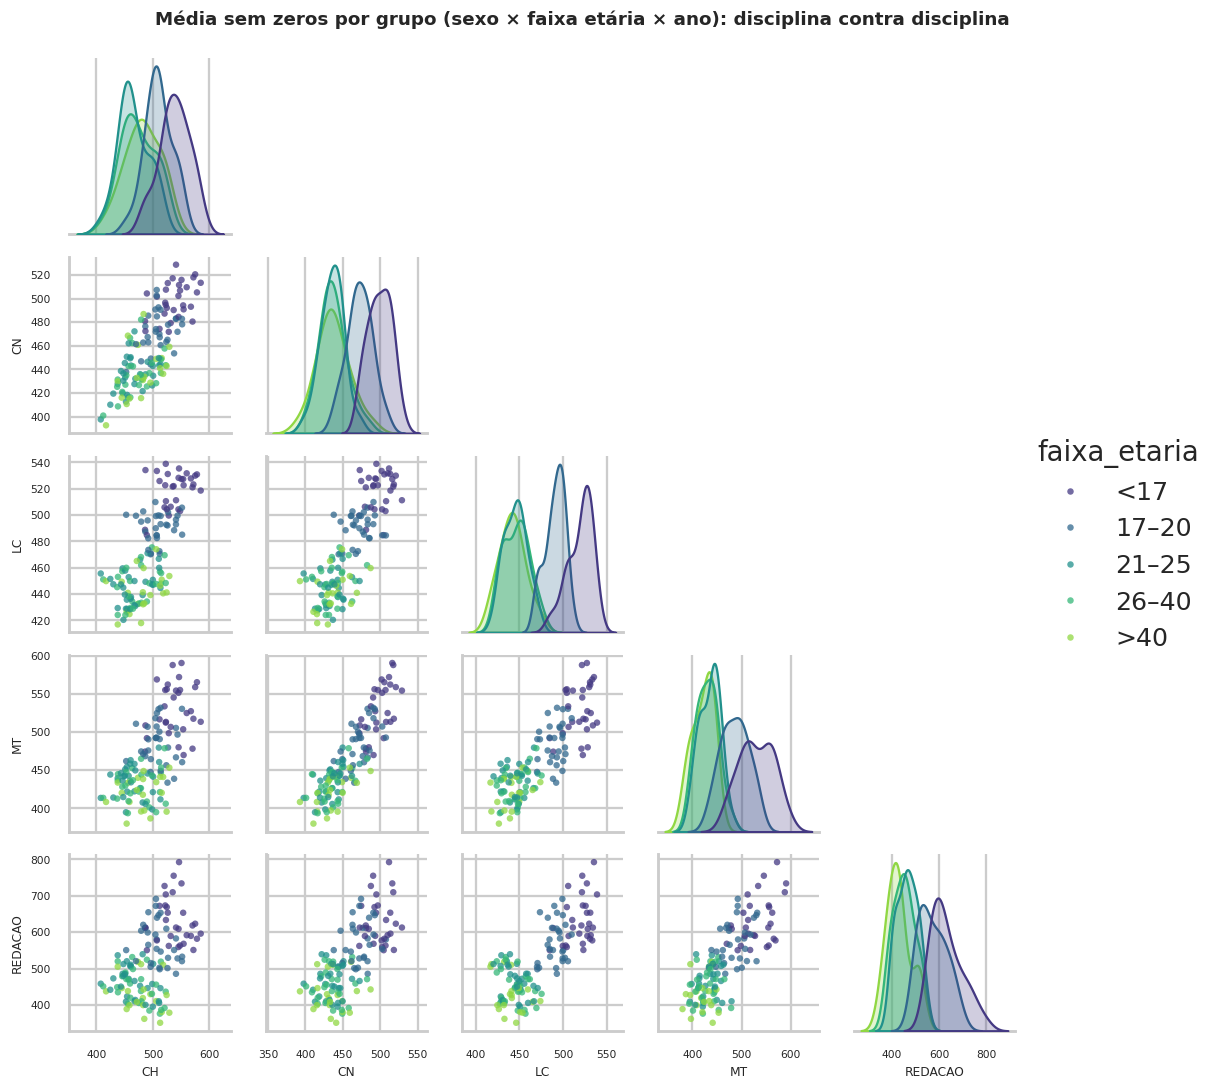

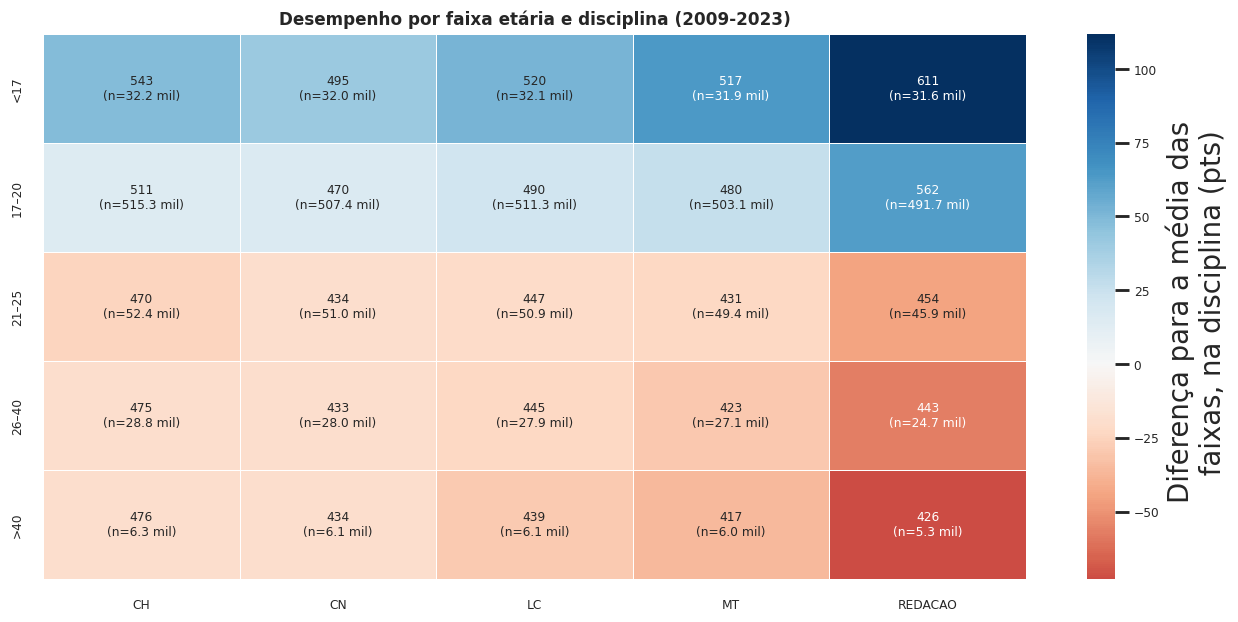

In [6]:
dsp_resumo = dsp_preparado.copy()
dsp_resumo["_soma"] = dsp_resumo["media"] * dsp_resumo["n_validos"]
dsp_resumo["_n_sem_zero"] = (dsp_resumo["n_validos"] - dsp_resumo["n_zeros"].fillna(0)).clip(lower=0)
dsp_resumo["_soma_sem_zero"] = dsp_resumo["media_positivas"] * dsp_resumo["_n_sem_zero"]
dsp_resumo = dsp_resumo.groupby(["ano", "disciplina", "sexo", "faixa_etaria"], as_index=False).agg(
    n_municipios=("CO_MUNICIPIO_TERRITORIO", "nunique"),
    n_validos=("n_validos", "sum"), n_zeros=("n_zeros", "sum"),
    soma_media=("_soma", "sum"), n_sem_zero=("_n_sem_zero", "sum"),
    soma_media_sem_zero=("_soma_sem_zero", "sum"),
)
dsp_resumo["media_ponderada"] = dsp_resumo["soma_media"] / dsp_resumo["n_validos"].where(dsp_resumo["n_validos"].gt(0))
dsp_resumo["media_ponderada_sem_zero"] = dsp_resumo["soma_media_sem_zero"] / dsp_resumo["n_sem_zero"].where(dsp_resumo["n_sem_zero"].gt(0))
#display(dsp_resumo)
#display(composicao_etaria.head(40))

ORDEM_FAIXA = ["<17", "17–20", "21–25", "26–40", ">40"]
DISC5 = ["CH", "CN", "LC", "MT", "REDACAO"]
CORES = {"CH": "#1f77b4", "CN": "#2ca02c", "LC": "#ff7f0e", "MT": "#9467bd", "REDACAO": "#d62728"}
ANO_PIRAMIDE = 2023
MIN_N = 100

d = dsp_resumo[dsp_resumo.ano >= 2009].copy()
d["faixa_etaria"] = pd.Categorical(d.faixa_etaria, categories=ORDEM_FAIXA, ordered=True)

w = (d[d.n_sem_zero >= MIN_N]
     .pivot_table(index=["ano", "sexo", "faixa_etaria"], columns="disciplina",
                  values="media_ponderada_sem_zero", observed=True)[DISC5].dropna().reset_index())

g = sns.pairplot(w, vars=DISC5, hue="faixa_etaria", hue_order=ORDEM_FAIXA,
                 palette="viridis", corner=True, height=2.0,
                 plot_kws={"s": 18, "alpha": 0.75, "edgecolor": "none"},
                 diag_kws={"common_norm": False})
g.figure.suptitle("Média sem zeros por grupo (sexo × faixa etária × ano): disciplina contra disciplina",
                  y=1.02, fontsize=12, fontweight="bold")
for ax in g.axes.flat:
    if ax is not None:
        ax.tick_params(labelsize=7); ax.xaxis.label.set_size(8); ax.yaxis.label.set_size(8)
plt.show()

#print(w[DISC5].corr().round(2))     # correlação entre disciplinas
ANO_INI, ANO_FIM = 2009, 2023

d = dsp_resumo[(dsp_resumo.ano >= ANO_INI) & (dsp_resumo.ano <= ANO_FIM)]
g = (d.groupby(["faixa_etaria", "disciplina"])
       .agg(soma=("soma_media_sem_zero", "sum"), n=("n_sem_zero", "sum")).reset_index())
g["media"] = g.soma / g.n

media = g.pivot(index="faixa_etaria", columns="disciplina", values="media").loc[ORDEM_FAIXA, DISC5]
n = g.pivot(index="faixa_etaria", columns="disciplina", values="n").loc[ORDEM_FAIXA, DISC5]
rotulo = media.round(0).astype(int).astype(str) + "\n(n=" + (n / 1000).round(1).astype(str) + " mil)"

# Cor = média da faixa menos a média da disciplina (compara faixas dentro da prova)
dif = media - media.mean()

fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(dif, annot=rotulo, fmt="", cmap="RdBu", center=0, linewidths=.5,
            linecolor="white", annot_kws={"fontsize": 8},
            cbar_kws={"label": f'Diferença para a média das \n faixas, na disciplina (pts)'}, ax=ax)
ax.set_title(f"Desempenho por faixa etária e disciplina ({ANO_INI}-{ANO_FIM})",
             fontsize=11, fontweight="bold")
ax.set_xlabel(""); ax.set_ylabel("")
ax.tick_params(labelsize=8); ax.figure.axes[-1].tick_params(labelsize=8)
plt.tight_layout(); plt.show()

### Comentários
As disciplinas apresentam padrões distintos de desempenho. Para 2023, a agregação dos resultados por sexo e faixa etária permite observar as seguintes médias ponderadas:

| Disciplina                | Média ponderada |
| ------------------------- | --------------- |
| Ciências Humanas (CH)     | 504,8           |
| Ciências da Natureza (CN) | 479,0           |
| Linguagens e Códigos (LC) | 497,5           |
| Matemática (MT)           | 504,5           |
| Redação                   | 628,0           |

Entre as provas objetivas em 2023, Ciências Humanas registrou a maior média ponderada, seguida de perto por Matemática, enquanto Linguagens e Códigos apresentou desempenho intermediário e Ciências da Natureza, a menor média. A Redação manteve a maior média geral entre todas as disciplinas.

A ocorrência de notas zero ajuda a explicar parte desse comportamento. Na Redação, elas corresponderam a cerca de 5,7% dos registros, ao passo que nas provas objetivas permaneceram abaixo de 0,6% (0,22% em CH, 0,51% em CN, 0,06% em LC e 0,52% em MT).

Quando se filtram apenas as notas positivas, o impacto é particularmente evidente na Redação, cuja média ponderada sobe de 628,0 para cerca de 665,9 pontos. Nas provas objetivas, os acréscimos são mais discretos:

* Ciências Humanas: de 504,8 para 505,9 pontos;

* Ciências da Natureza: de 479,0 para 481,4 pontos;

* Linguagens e Códigos: de 497,5 para 497,8 pontos;

* Matemática: de 504,5 para 507,2 pontos.

**Variação por faixa etária**
Na análise por faixa etária, consideraram-se as médias ponderadas das notas positivas agrupadas por idade e disciplina, avaliadas como desvios em relação à média geral de cada prova e não como diferenças absolutas entre áreas do conhecimento.

O padrão observado se repete nas cinco disciplinas:

* Até 20 anos (desvios positivos): os participantes com menos de 17 anos alcançam os maiores desvios positivos em todas as áreas, com destaque para a Redação (+111,8 pontos). A faixa de 17–20 anos também apresenta desvios positivos, porém de menor magnitude (variando de +15,8 pontos em Ciências Humanas a +62,5 pontos em Redação).

* A partir de 21 anos (desvios negativos): os desvios tornam-se negativos em todas as disciplinas nas faixas de 21–25, 26–40 e acima de 40 anos. Na Redação, os valores atingem −45,3 pontos (21–25 anos), −56,2 pontos (26–40 anos) e −72,8 pontos (acima de 40 anos). Nas provas objetivas, as quedas são menores — por exemplo, em Matemática, vão de −23,0 pontos (21–25 anos) a −36,6 pontos (acima de 40 anos), e em Ciências Humanas, situam-se em −24,6 pontos e −19,3 pontos, respectivamente.

Em síntese, as diferenças etárias seguem uma tendência comum às cinco provas, mas com maior amplitude na Redação. Como os resultados são expressos em relação à média de cada disciplina e cada prova possui estrutura avaliativa e distribuição próprias, esses valores não devem ser tomados isoladamente como medida direta de dificuldade nem como evidência causal entre idade e desempenho.


## 6. Síntese dos resultados

A análise da distribuição do desempenho no ENEM no Pará evidencia que as diferenças observadas não seguem uma tendência única. A variabilidade das notas, a distribuição das médias municipais e as diferenças entre grupos de participantes apresentam comportamentos distintos conforme a disciplina e o período considerado. Esse conjunto de resultados reforça a importância de analisar o desempenho para além das médias gerais, incorporando também medidas de dispersão e características da composição dos grupos avaliados.

Entre 2009 e 2025, a evolução dos indicadores de dispersão foi distinta entre as áreas do conhecimento. 
* Ciências Humanas, Ciências da Natureza e Linguagens apresentaram redução do desvio-padrão combinado aproximado, embora os indicadores baseados no IQR municipal não tenham acompanhado essa redução de maneira uniforme.
*  Matemática apresentou comportamento diferente, com ampliação expressiva da dispersão em relação a 2009. Apesar do recuo observado entre 2023 e 2025, seus indicadores permaneceram acima dos valores iniciais da série.
*   Na Redação, houve redução da dispersão em relação a 2009, mas os resultados ainda apresentam variabilidade elevada quando comparados às provas objetivas.

As mudanças na distribuição das médias municipais também não foram homogêneas.
* Em Ciências Humanas e Ciências da Natureza, os quartis inferior e superior aumentaram moderadamente entre 2009 e 2025.
*  Em Linguagens, a elevação foi mais expressiva, enquanto a Redação apresentou os maiores avanços nos dois quartis, acompanhados de redução da distância entre eles.
*  Matemática, por sua vez, registrou diminuição do quartil inferior e pequena redução do superior, ampliando a distância entre essas referências.

**Diferenças territoriais**

A evolução das médias municipais não seguiu o mesmo padrão em todas as disciplinas. Matemática apresentou aumento da dispersão em relação a 2009, enquanto Ciências Humanas, Ciências da Natureza e Linguagens tiveram redução em alguns indicadores de dispersão. Portanto, não houve uma redução generalizada das diferenças de desempenho entre os municípios do Pará.

**Diferenças entre grupos de participantes**

Em 2023, as diferenças de desempenho entre as faixas etárias foram maiores do que aquelas observadas entre os grupos de sexo e de dependência administrativa nas cinco disciplinas. Esse resultado foi especialmente expressivo em Matemática e Redação.

O desempenho também variou de acordo com a faixa etária: participantes com menos de 21 anos apresentaram médias acima da média geral das disciplinas, enquanto aqueles com 21 anos ou mais ficaram abaixo dela. A diferença foi particularmente acentuada em Redação. Esse resultado descreve uma associação entre faixa etária e desempenho, mas não permite afirmar que a idade, isoladamente, explique essas diferenças.

**Diferenças entre redes de ensino**

Em 2025, as escolas privadas apresentaram médias superiores às estaduais em todas as disciplinas. As maiores diferenças ocorreram em Redação e Matemática. As escolas federais também tiveram médias superiores às estaduais. Essas comparações devem considerar, entretanto, a cobertura limitada de algumas categorias, especialmente das escolas municipais no último ano da série.

**Diferenças entre disciplinas**

Em 2023, as médias das provas objetivas ficaram próximas, entre 479,0 pontos em Ciências da Natureza e 504,8 em Ciências Humanas. Redação apresentou média mais elevada, de 628,0 pontos.

Essa média foi influenciada pela presença de notas zero, que corresponderam a aproximadamente 5,7% dos registros de Redação, enquanto nas provas objetivas a proporção ficou abaixo de 0,6%. Quando as notas zero foram excluídas, a média da Redação passou de 628,0 para aproximadamente 665,9 pontos. Assim, a média agregada dessa disciplina deve ser interpretada considerando a participação expressiva das notas zero.


Os resultados apontam três aspectos centrais: o aumento da dispersão municipal em Matemática, as diferenças expressivas de desempenho entre faixas etárias e redes de ensino e a influência das notas zero sobre a média de Redação. Esses resultados mostram que a desigualdade de desempenho no ENEM no Pará não se manifesta de uma única forma: varia conforme a disciplina, o município e o grupo de participantes analisado.

 <div style="background-color: #E2E8F0; padding: 12px; border-radius: 6px;">
    
**Síntese Final**  
Dessa forma, os resultados apontam três aspectos centrais: o aumento da dispersão municipal em Matemática, as diferenças expressivas de desempenho entre faixas etárias e redes de ensino e a influência das notas zero sobre a média de Redação. Esses resultados mostram que a desigualdade de desempenho no ENEM no Pará não se manifesta de uma única forma: varia conforme a disciplina, o município e o grupo de participantes analisado.
</div>
